# Laporan Source Code UAS IR Kelompok 4

Mata Kuliah: Temu Kembali Informasi

Dosen Pengampu: Novi  Yusliani, S.Kom., M.T

Anggota Kelompok 4:
1. Nurul Adhaini Nasution (09021282328125)
2. Githa Evelyn (09021282328124)
3. Putri Alimah Azizah (09021282328069)
4. Erlangga Saputra (09021282328100)


# 1. Import Library dan Konfigurasi Awal

Memuat seluruh pustaka Python yang diperlukan dan mengunci nilai SEED = 42 agar pembagian 5-Fold serta proses pelatihan pohon keputusan menghasilkan angka yang konsisten setiap kali dijalankan.

In [4]:
import re
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import GroupKFold

import lightgbm
from lightgbm import LGBMRanker
from scipy.stats import wilcoxon

import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

print(f"Library berhasil diimport. LightGBM version: {lightgbm.__version__}")

Library berhasil diimport. LightGBM version: 4.6.0


# 2. Load Data & EDA Dataset

Menelusuri file metadata.csv, topics-rnd3.csv, dan qrels.csv secara otomatis di direktori input Kaggle, memuatnya ke DataFrame, lalu menjalankan EDA awal.

In [2]:
DATA_DIR = Path("/kaggle/input/competitions/trec-covid-information-retrieval")

metadata_path = next(DATA_DIR.rglob("metadata.csv"))
topics_path = next(DATA_DIR.rglob("topics-rnd3.csv"))
qrels_path = next(DATA_DIR.rglob("qrels.csv"))

metadata = pd.read_csv(metadata_path)
topics = pd.read_csv(topics_path)
qrels = pd.read_csv(qrels_path)

print("Metadata:", metadata.shape, "| Topics:", topics.shape, "| Qrels:", qrels.shape)

Metadata: (128492, 19) | Topics: (40, 4) | Qrels: (20728, 4)


EXPLORATORY DATA ANALYSIS (EDA) AWAL - TREC-COVID ROUND 3

Metadata shape : (128492, 19)
Topics shape   : (40, 4)
Qrels shape    : (20728, 4)

Kolom Metadata : ['cord_uid', 'sha', 'source_x', 'title', 'doi', 'pmcid', 'pubmed_id', 'license', 'abstract', 'publish_time', 'authors', 'journal', 'mag_id', 'who_covidence_id', 'arxiv_id', 'pdf_json_files', 'pmc_json_files', 'url', 's2_id']
Kolom Topics   : ['topic-id', 'query', 'question', 'narrative']
Kolom Qrels    : ['topic-id', 'iteration', 'cord-id', 'judgement']

--- EDA METADATA (DOKUMEN) ---
Jumlah baris metadata        : 128,492
Jumlah cord_uid unik         : 128,162
Duplikasi cord_uid di metadata : 330

Missing values kolom utama metadata:
              missing_count  missing_pct (%)
cord_uid                  0             0.00
title                    28             0.02
abstract              26882            20.92
publish_time             15             0.01
journal                6297             4.90
source_x                  0  

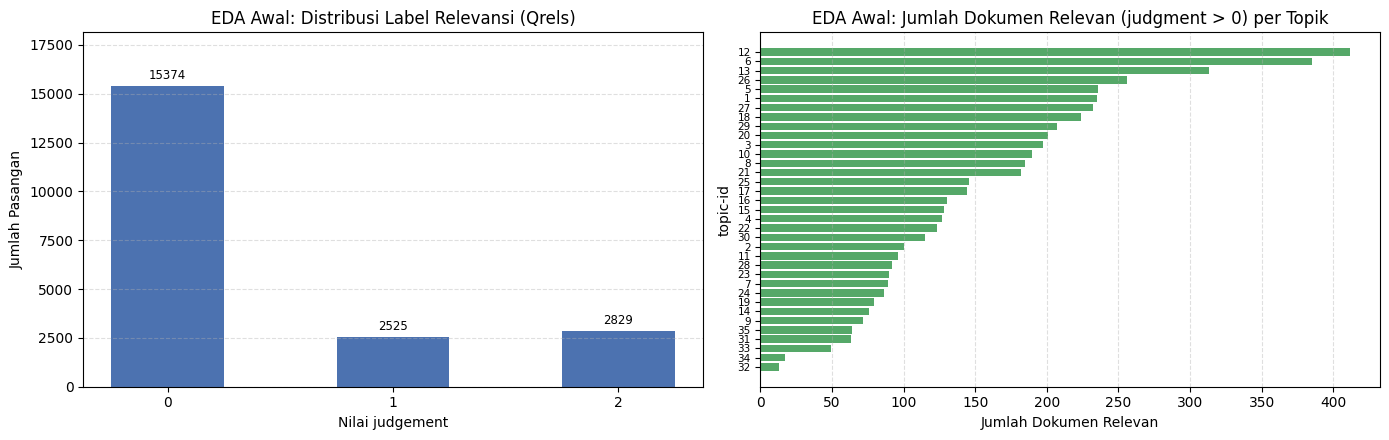

In [5]:

# LOAD DATA & EXPLORATORY DATA ANALYSIS (EDA) AWAL (SEBELUM PREPROCESSING)
DATA_DIR = Path("/kaggle/input/competitions/trec-covid-information-retrieval")

metadata_path = next(DATA_DIR.rglob("metadata.csv"))
topics_path = next(DATA_DIR.rglob("topics-rnd3.csv"))
qrels_path = next(DATA_DIR.rglob("qrels.csv"))

metadata = pd.read_csv(metadata_path)
topics = pd.read_csv(topics_path)
qrels = pd.read_csv(qrels_path)

print("=" * 70)
print("EXPLORATORY DATA ANALYSIS (EDA) AWAL - TREC-COVID ROUND 3")
print("=" * 70)

# 1. Dimensi & Kolom Utama
print(f"\nMetadata shape : {metadata.shape}")
print(f"Topics shape   : {topics.shape}")
print(f"Qrels shape    : {qrels.shape}")

print("\nKolom Metadata :", list(metadata.columns))
print("Kolom Topics   :", list(topics.columns))
print("Kolom Qrels    :", list(qrels.columns))

# Deteksi otomatis nama kolom kunci bila berbeda
topic_col_qrels = "topic_id" if "topic_id" in qrels.columns else ("query-id" if "query-id" in qrels.columns else qrels.columns[0])
doc_col_qrels = "cord_uid" if "cord_uid" in qrels.columns else ("doc-id" if "doc-id" in qrels.columns else qrels.columns[1])
rel_col_qrels = "judgment" if "judgment" in qrels.columns else ("score" if "score" in qrels.columns else qrels.columns[-1])

# 2. EDA Metadata (Korpus Dokumen)
print("\n--- EDA METADATA (DOKUMEN) ---")
if "cord_uid" in metadata.columns:
    print(f"Jumlah baris metadata        : {len(metadata):,}")
    print(f"Jumlah cord_uid unik         : {metadata['cord_uid'].nunique():,}")
    print(f"Duplikasi cord_uid di metadata : {metadata['cord_uid'].duplicated().sum():,}")

meta_focus_cols = [c for c in ["cord_uid", "title", "abstract", "publish_time", "journal", "source_x"] if c in metadata.columns]
if meta_focus_cols:
    meta_missing = pd.DataFrame({
        "missing_count": metadata[meta_focus_cols].isna().sum(),
        "missing_pct (%)": (metadata[meta_focus_cols].isna().sum() / len(metadata) * 100).round(2)
    })
    print("\nMissing values kolom utama metadata:")
    print(meta_missing.to_string())

if "title" in metadata.columns:
    title_wc = metadata["title"].fillna("").str.split().str.len()
    print(f"Panjang judul (kata) - mean: {title_wc.mean():.2f}, median: {title_wc.median():.1f}, max: {title_wc.max()}")

if "abstract" in metadata.columns:
    abs_wc = metadata["abstract"].fillna("").str.split().str.len()
    non_empty_abs = abs_wc[abs_wc > 0]
    print(f"Jumlah dokumen ber-abstrak   : {len(non_empty_abs):,} ({len(non_empty_abs)/len(metadata)*100:.2f}%)")
    if len(non_empty_abs) > 0:
        print(f"Panjang abstrak (kata) - mean: {non_empty_abs.mean():.2f}, median: {non_empty_abs.median():.1f}, >150 kata: {(non_empty_abs > 150).sum():,}")

# 3. EDA Topics (Topik / Kueri)
print("\n--- EDA TOPICS ---")
topic_col_topics = "topic_id" if "topic_id" in topics.columns else ("query-id" if "query-id" in topics.columns else topics.columns[0])
print(f"Jumlah baris topics          : {len(topics)}")
print(f"Jumlah topik unik            : {topics[topic_col_topics].nunique()}")
print("Missing values di topics:")
print(topics.isna().sum().to_string())

for q_col in ["query", "question", "narrative"]:
    if q_col in topics.columns:
        wc = topics[q_col].fillna("").str.split().str.len()
        print(f"Panjang '{q_col}' (kata) - mean: {wc.mean():.2f}, min: {wc.min()}, max: {wc.max()}")

# 4. EDA Qrels (Relevansi / Judgment)
print("\n--- EDA QRELS (RELEVANSI) ---")
print(f"Jumlah baris qrels           : {len(qrels):,}")
print(f"Jumlah topik di qrels        : {qrels[topic_col_qrels].nunique()}")
print(f"Duplikasi ({topic_col_qrels}, {doc_col_qrels}): {qrels.duplicated(subset=[topic_col_qrels, doc_col_qrels]).sum():,}")

if "cord_uid" in metadata.columns and doc_col_qrels in qrels.columns:
    matched_docs = qrels[doc_col_qrels].isin(set(metadata["cord_uid"])).sum()
    print(f"Qrels yang cocok dgn metadata: {matched_docs:,} / {len(qrels):,} ({matched_docs/len(qrels)*100:.2f}%)")

judgment_counts = qrels[rel_col_qrels].value_counts(dropna=False).sort_index()
judgment_dist = pd.DataFrame({
    "jumlah": judgment_counts,
    "persentase (%)": (judgment_counts / len(qrels) * 100).round(2)
})
print("\nDistribusi label relevansi di qrels:")
print(judgment_dist.to_string())

qrels_per_topic = qrels.groupby(topic_col_qrels).agg(
    total_judged=(doc_col_qrels, "count"),
    rel_docs=(rel_col_qrels, lambda s: (s > 0).sum()),
    high_rel_docs=(rel_col_qrels, lambda s: (s >= 2).sum())
)
qrels_per_topic["rel_ratio (%)"] = (qrels_per_topic["rel_docs"] / qrels_per_topic["total_judged"] * 100).round(2)

print("\nRingkasan statistik qrels per topik:")
print(qrels_per_topic.describe().round(2).to_string())

# 5. Simpan Ringkasan EDA ke CSV
judgment_dist.reset_index().rename(columns={"index": rel_col_qrels}).to_csv("eda_distribusi_judgment_qrels.csv", index=False)
qrels_per_topic.reset_index().to_csv("eda_qrels_per_topik.csv", index=False)

# 6. Visualisasi EDA Awal (Distribusi Judgment & Dokumen Relevan per Topik di Qrels)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax0 = axes[0]
bars_j = ax0.bar(
    judgment_dist.index.astype(str),
    judgment_dist["jumlah"],
    color="#4C72B0",
    width=0.5
)
ax0.set_title("EDA Awal: Distribusi Label Relevansi (Qrels)")
ax0.set_xlabel(f"Nilai {rel_col_qrels}")
ax0.set_ylabel("Jumlah Pasangan")
ax0.set_ylim(0, judgment_dist["jumlah"].max() * 1.18)
ax0.grid(axis="y", linestyle="--", alpha=0.4)
ax0.bar_label(bars_j, fmt="%d", padding=3, fontsize=8.5)

ax1 = axes[1]
topic_sorted = qrels_per_topic.sort_values("rel_docs", ascending=True)
ax1.barh(topic_sorted.index.astype(str), topic_sorted["rel_docs"], color="#55A868")
ax1.set_title("EDA Awal: Jumlah Dokumen Relevan (judgment > 0) per Topik")
ax1.set_xlabel("Jumlah Dokumen Relevan")
ax1.set_ylabel(topic_col_qrels)
ax1.grid(axis="x", linestyle="--", alpha=0.4)
if len(topic_sorted) > 20:
    ax1.tick_params(axis="y", labelsize=7.5)

plt.tight_layout()
plt.savefig("eda_awal_trec_covid.png", dpi=300, bbox_inches="tight")
plt.show()

### Ringkasan Exploratory Data Analysis (EDA)

- **Korpus Dokumen (`metadata.csv`):** Terdiri dari **128.492** entri (**128.162** `cord_uid` unik; **330** duplikat). Sebanyak **101.610** dokumen (**79,08%**) memiliki abstrak, sedangkan **26.882** (**20,92%**) tidak berabstrak. Rata-rata panjang judul adalah **12,44 kata** (median `12.0`), dan rata-rata panjang abstrak mencapai **197,94 kata** (median `197.0`), dengan **70.369** dokumen memiliki abstrak **> 150 kata**.
- **Topik & Penilaian Relevansi (`topics-rnd3.csv` & `qrels.csv`):** Dari **40** topik yang tersedia, hanya **35 topik** yang memiliki penilaian relevansi pakar (`20.728` baris penilaian), sehingga seluruh eksperimen difokuskan pada irisan **35 topik** valid tersebut. Distribusi label relevansi meliputi label `0` (**74,17%** / `15.374`), label `1` (**12,18%** / `2.525`), dan label `2` (**13,65%** / `2.829`), dengan rata-rata **592,23** dokumen dinilai dan **152,97** dokumen relevan (`25,26%`) per topik.
- **Implikasi Desain:** Dominasi abstrak panjang (>150 kata) mendasari ekstraksi **fitur tingkat *passage*** (jendela geser 40 token) agar konsentrasi kecocokan kueri lokal tidak tereduksi panjang teks, sementara variasi jumlah dokumen relevan antar-topik (`13`–`412`) mendasari penerapan **normalisasi Min-Max per topik** dan validasi **5-Fold GroupKFold**.

# 3. Preprocessing, Perluasan Kueri, dan Parameter Eksperimen

Selain membersihkan teks judul dan abstrak, pada tahap ini dibuat kolom baru bernama full_query yang menggabungkan kata kunci singkat (query) dengan kalimat pertanyaan lengkap (question) pada dataset topik.
* 3a. Pembersihan Teks Artikel: Menghapus duplikasi cord_uid, mengubah huruf ke huruf kecil, membuang tag HTML serta tanda baca, lalu menggabungkan judul dan abstrak.

In [6]:
metadata.columns = [c.strip().lower() for c in metadata.columns]
metadata = metadata[["cord_uid", "title", "abstract"]].copy()
metadata["cord_uid"] = metadata["cord_uid"].astype(str).str.strip()
metadata["title"] = metadata["title"].fillna("").astype(str)
metadata["abstract"] = metadata["abstract"].fillna("").astype(str)

metadata = metadata.drop_duplicates(subset="cord_uid")
metadata = metadata[
    (metadata["title"].str.len() > 0) | (metadata["abstract"].str.len() > 0)
].reset_index(drop=True)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

metadata["title_clean"] = metadata["title"].apply(clean_text)
metadata["abstract_clean"] = metadata["abstract"].apply(clean_text)
metadata["document_text"] = (metadata["title_clean"] + " " + metadata["abstract_clean"]).str.strip()

print("Jumlah metadata bersih:", len(metadata))

Jumlah metadata bersih: 128139


* 3b. Penyelarasan Topics (Full Query) & Qrels: Menggabungkan kolom query dan question menjadi full_query agar informasi pencarian lebih lengkap, menyaring 35 topik valid, dan menetapkan parameter eksperimen.

In [7]:
topics.columns = [c.strip().lower() for c in topics.columns]
topics = topics.rename(columns={"topic-id": "topic_id"})
topics["topic_id"] = pd.to_numeric(topics["topic_id"], errors="coerce")
topics = topics.dropna(subset=["topic_id", "query"]).copy()
topics["topic_id"] = topics["topic_id"].astype(int)
topics["query"] = topics["query"].fillna("").astype(str)
topics["question"] = topics["question"].fillna("").astype(str)

# PENINGKATAN 1: Gabungkan query dan question menjadi full_query
topics["full_query"] = (topics["query"] + " " + topics["question"]).str.strip()

qrels.columns = [c.strip().lower() for c in qrels.columns]
qrels = qrels.rename(columns={"topic-id": "topic_id", "cord-id": "cord_uid", "judgement": "judgment"})
qrels["topic_id"] = pd.to_numeric(qrels["topic_id"], errors="coerce")
qrels["judgment"] = pd.to_numeric(qrels["judgment"], errors="coerce")
qrels["cord_uid"] = qrels["cord_uid"].astype(str).str.strip()
qrels = qrels.dropna(subset=["topic_id", "judgment", "cord_uid"]).copy()
qrels["topic_id"] = qrels["topic_id"].astype(int)
qrels["judgment"] = qrels["judgment"].astype(int)
qrels = qrels.groupby(["topic_id", "cord_uid"], as_index=False)["judgment"].max()

valid_topic_ids = sorted(set(topics["topic_id"]) & set(qrels["topic_id"]))
topics = topics[topics["topic_id"].isin(valid_topic_ids)].sort_values("topic_id").reset_index(drop=True)

# Parameter Eksperimen
TOP_K = 1000
RERANK_DEPTH = 100
PASSAGE_LENGTH = 40
PASSAGE_OVERLAP = 10
MAX_PASSAGES = 20
N_SPLITS = 5
K1 = 1.5
B = 0.75

print("Jumlah topik valid:", len(topics))
print("Contoh full_query topik 1:", topics.loc[0, "full_query"])

Jumlah topik valid: 35
Contoh full_query topik 1: coronavirus origin what is the origin of COVID-19


# 4. Pembagunan Indeks & Candidate Retrieval BM25

Membangun indeks matriks jarang (CSC Sparse Matrix) dari seluruh artikel, lalu mencari 1.000 kandidat terbaik per topik menggunakan full_query. Perhatikan peningkatan nilai Candidate Recall@1000 dibandingkan sebelumnya karena kata kunci dari kolom question kini ikut dicari.

In [8]:
start_time = time.time()

vectorizer = CountVectorizer(
    stop_words="english",
    min_df=2,
    max_features=100000,
    dtype=np.int32
)

X = vectorizer.fit_transform(metadata["document_text"])
X_csc = X.tocsc()
vocabulary = vectorizer.vocabulary_
analyzer = vectorizer.build_analyzer()

N = X.shape[0]
doc_lengths = np.asarray(X.sum(axis=1)).ravel()
avgdl = doc_lengths.mean()

df = np.asarray((X > 0).sum(axis=0)).ravel()
idf = np.log(1 + (N - df + 0.5) / (df + 0.5))
length_norm = K1 * (1 - B + B * doc_lengths / avgdl)

def bm25_search(query_text, top_k=1000):
    query_terms = set(analyzer(query_text))
    scores = np.zeros(N, dtype=np.float32)

    for term in query_terms:
        term_id = vocabulary.get(term)
        if term_id is None:
            continue
        start, end = X_csc.indptr[term_id], X_csc.indptr[term_id + 1]
        rows = X_csc.indices[start:end]
        frequencies = X_csc.data[start:end]
        scores[rows] += idf[term_id] * (frequencies * (K1 + 1)) / (frequencies + length_norm[rows])

    valid_indices = np.flatnonzero(scores > 0)
    if len(valid_indices) == 0:
        return np.array([], dtype=int), np.array([])

    k = min(top_k, len(valid_indices))
    top_indices = valid_indices[np.argpartition(scores[valid_indices], -k)[-k:]]
    top_indices = top_indices[np.argsort(scores[top_indices])[::-1]]
    return top_indices, scores[top_indices]

candidate_results = []
for _, topic in topics.iterrows():
    topic_id = topic["topic_id"]
    indices, scores = bm25_search(str(topic["full_query"]), top_k=TOP_K)
    selected = metadata.iloc[indices][
        ["cord_uid", "title_clean", "abstract_clean", "document_text"]
    ].copy()
    selected["topic_id"] = topic_id
    selected["bm25_score"] = scores
    candidate_results.append(selected)

candidates = pd.concat(candidate_results, ignore_index=True)

# Evaluasi Candidate Recall@1000
recalls = []
for topic_id in topics["topic_id"]:
    rel_ids = set(qrels.loc[(qrels["topic_id"] == topic_id) & (qrels["judgment"] > 0), "cord_uid"])
    ret_ids = set(candidates.loc[candidates["topic_id"] == topic_id, "cord_uid"])
    recalls.append(len(rel_ids & ret_ids) / len(rel_ids) if len(rel_ids) > 0 else 0.0)

print(f"Retrieval selesai dalam {time.time() - start_time:.2f} detik.")
print(f"Rata-rata Candidate Recall@1000 (dengan Full Query): {np.mean(recalls):.4f}")

Retrieval selesai dalam 14.76 detik.
Rata-rata Candidate Recall@1000 (dengan Full Query): 0.3864


# 5. Ekstraksi 13 Fitur (Dokumen, Passage, dan Rasio Konsetrasi

Pada 100 kandidat teratas tiap topik (RERANK_DEPTH = 100), diekstrak 8 fitur dokumen dan 5 fitur passage. Dua fitur rasio baru ditambahkan untuk membantu pohon keputusan membedakan relevansi tinggi:
* title_doc_ratio: Perbandingan skor BM25 judul terhadap abstrak. Dokumen yang memuat kata kunci tepat di judul cenderung memiliki relevansi jauh lebih tinggi.
* passage_peak_ratio: Perbandingan skor passage tertinggi (passage_max) terhadap skor rata-rata seluruh passage (passage_mean). Nilai tinggi menandakan ada satu segmen paragraf yang sangat fokus menjawab pertanyaan pengguna.

In [9]:
def tokenize_in_vocab(text):
    return [t for t in analyzer(text) if t in vocabulary]

query_map = dict(zip(topics["topic_id"], topics["full_query"]))
idf_dict = {term: float(idf[index]) for term, index in vocabulary.items()}

avg_title_length = max(metadata["title_clean"].apply(lambda x: len(tokenize_in_vocab(x))).mean(), 1.0)
avg_abstract_length = max(metadata["abstract_clean"].apply(lambda x: len(tokenize_in_vocab(x))).mean(), 1.0)

def score_tokens_bm25(tokens, query_terms, avg_length):
    doc_length = len(tokens)
    if doc_length == 0:
        return 0.0
    frequencies = Counter(tokens)
    score = 0.0
    for term in query_terms:
        tf = frequencies.get(term, 0)
        if tf == 0:
            continue
        term_idf = idf_dict.get(term, 0.0)
        denominator = tf + K1 * (1 - B + B * doc_length / avg_length)
        score += term_idf * tf * (K1 + 1) / denominator
    return score

def split_passages(tokens, passage_length=PASSAGE_LENGTH, overlap=PASSAGE_OVERLAP):
    if not tokens:
        return []
    passages = []
    step = max(passage_length - overlap, 1)
    for start in range(0, len(tokens), step):
        passage = tokens[start:start + passage_length]
        if not passage:
            break
        passages.append(passage)
        if start + passage_length >= len(tokens):
            break
    return passages[:MAX_PASSAGES]

sample_lengths = []
for text in candidates["document_text"].iloc[:5000]:
    sample_lengths.extend([len(p) for p in split_passages(tokenize_in_vocab(text))])
avg_passage_length = max(np.mean(sample_lengths), 1.0)

def extract_all_features(row):
    query_terms = set(tokenize_in_vocab(query_map[row["topic_id"]]))
    title_tokens = tokenize_in_vocab(row["title_clean"])
    abstract_tokens = tokenize_in_vocab(row["abstract_clean"])
    doc_tokens = title_tokens + abstract_tokens

    title_terms = set(title_tokens)
    abstract_terms = set(abstract_tokens)
    doc_terms = title_terms | abstract_terms

    q_len = max(len(query_terms), 1)
    query_coverage = len(query_terms & doc_terms) / q_len
    title_coverage = len(query_terms & title_terms) / q_len
    abstract_coverage = len(query_terms & abstract_terms) / q_len

    bm25_title = score_tokens_bm25(title_tokens, query_terms, avg_title_length)
    bm25_abstract = score_tokens_bm25(abstract_tokens, query_terms, avg_abstract_length)
    doc_length = len(doc_tokens)
    title_doc_ratio = bm25_title / (bm25_abstract + 1e-5)

    passages = split_passages(doc_tokens)
    if len(passages) == 0:
        p_max, p_mean, p_top3, p_count, p_peak = 0.0, 0.0, 0.0, 0, 0.0
    else:
        p_scores = np.array([score_tokens_bm25(p, query_terms, avg_passage_length) for p in passages], dtype=np.float32)
        p_max = float(p_scores.max())
        p_mean = float(p_scores.mean())
        p_top3 = float(np.sort(p_scores)[-3:].mean())
        p_count = len(p_scores)
        p_peak = p_max / (p_mean + 1e-5)

    return pd.Series({
        "bm25_title": bm25_title,
        "bm25_abstract": bm25_abstract,
        "query_coverage": query_coverage,
        "title_coverage": title_coverage,
        "abstract_coverage": abstract_coverage,
        "doc_length": doc_length,
        "title_doc_ratio": title_doc_ratio,
        "passage_max": p_max,
        "passage_mean": p_mean,
        "passage_top3_mean": p_top3,
        "passage_count": p_count,
        "passage_peak_ratio": p_peak
    })

start_time = time.time()
rerank_pool = (
    candidates.sort_values(["topic_id", "bm25_score"], ascending=[True, False])
    .groupby("topic_id", as_index=False)
    .head(RERANK_DEPTH)
    .reset_index(drop=True)
)

rerank_pool = pd.concat([rerank_pool, rerank_pool.apply(extract_all_features, axis=1)], axis=1)
print(f"Ekstraksi 13 fitur selesai dalam {time.time() - start_time:.2f} detik.")

Ekstraksi 13 fitur selesai dalam 1.69 detik.


# 6. Pelabelan Left Merge & Normalisasi Fitur Per Topik

Setelah menggabungkan kandidat Top-100 dengan qrels menggunakan Left Merge, seluruh fitur numerik dinormalisasi ke skala 0 hingga 1 di dalam setiap topik (groupby('topic_id')). Langkah ini menghilangkan perbedaan skala skor antar-kueri sehingga model LambdaMART belajar dari posisi relatif tiap dokumen.

In [10]:
data = rerank_pool.merge(
    qrels[["topic_id", "cord_uid", "judgment"]],
    on=["topic_id", "cord_uid"],
    how="left",
    validate="one_to_one"
)
data["judgment"] = data["judgment"].fillna(0).astype(int)

RAW_DOC_FEATURES = [
    "bm25_score", "bm25_title", "bm25_abstract",
    "query_coverage", "title_coverage", "abstract_coverage",
    "doc_length", "title_doc_ratio"
]

RAW_PASSAGE_FEATURES = [
    "passage_max", "passage_mean", "passage_top3_mean",
    "passage_count", "passage_peak_ratio"
]

ALL_RAW_FEATURES = RAW_DOC_FEATURES + RAW_PASSAGE_FEATURES

# PENINGKATAN 3: Query-Level Min-Max Normalization per topic_id
def minmax_per_topic(series):
    rng = series.max() - series.min()
    return (series - series.min()) / rng if rng > 0 else 0.0

for col in ALL_RAW_FEATURES:
    data[f"{col}_norm"] = data.groupby("topic_id")[col].transform(minmax_per_topic)

SYSTEM2_FEATURES = [f"{col}_norm" for col in RAW_DOC_FEATURES]
SYSTEM3_FEATURES = [f"{col}_norm" for col in ALL_RAW_FEATURES]

print("Total baris dataset LTR:", len(data))
print("Jumlah fitur Sistem 2:", len(SYSTEM2_FEATURES), "| Jumlah fitur Sistem 3:", len(SYSTEM3_FEATURES))
print("Distribusi label relevansi dalam pool kandidat:")
print(data["judgment"].value_counts().sort_index())

Total baris dataset LTR: 3500
Jumlah fitur Sistem 2: 8 | Jumlah fitur Sistem 3: 13
Distribusi label relevansi dalam pool kandidat:
judgment
0    2984
1     176
2     340
Name: count, dtype: int64


# 7. Definisi Fungsi Evaluasi & Training LambdaMART (Teregulasi)

Fungsi evaluate_ranking menghitung nDCG@10, MAP, Precision@10, dan Recall@100. Sementara itu, fungsi train_lambdamart menggunakan jumlah pohon yang ringkas (n_estimators=45, num_leaves=6) dan regularisasi L2 yang kuat (reg_lambda=5.0) agar model tidak overfitting pada 28 topik latih.

In [11]:
def evaluate_ranking(topic_id, ranked_df, qrels_df):
    topic_qrels = qrels_df[qrels_df["topic_id"] == topic_id]
    relevance = dict(zip(topic_qrels["cord_uid"], topic_qrels["judgment"]))

    ranked = ranked_df.sort_values("predicted_score", ascending=False)
    ranked_ids = ranked["cord_uid"].tolist()
    rel = np.array([relevance.get(doc_id, 0) for doc_id in ranked_ids], dtype=float)

    k = 10
    top_rel = rel[:k]
    dcg = np.sum((2 ** top_rel - 1) / np.log2(np.arange(2, len(top_rel) + 2)))

    ideal_rel = sorted(topic_qrels["judgment"].tolist(), reverse=True)[:k]
    idcg = np.sum((2 ** np.array(ideal_rel) - 1) / np.log2(np.arange(2, len(ideal_rel) + 2)))
    ndcg = dcg / idcg if idcg > 0 else 0.0

    relevant_ids = set(topic_qrels.loc[topic_qrels["judgment"] > 0, "cord_uid"])
    total_relevant = len(relevant_ids)
    precision = np.sum(top_rel > 0) / k
    recall = len(set(ranked_ids[:100]) & relevant_ids) / total_relevant if total_relevant > 0 else 0.0

    hits = 0
    precision_sum = 0.0
    for rank, doc_id in enumerate(ranked_ids, start=1):
        if doc_id in relevant_ids:
            hits += 1
            precision_sum += hits / rank
    average_precision = precision_sum / total_relevant if total_relevant > 0 else 0.0

    return {
        "topic_id": topic_id,
        "nDCG@10": ndcg,
        "MAP": average_precision,
        "Precision@10": precision,
        "Recall@100": recall
    }

# PENINGKATAN 4: Konfigurasi LGBMRanker tahan overfitting untuk dataset 35 topik
def train_lambdamart(train_df, feature_columns):
    train_df = train_df.sort_values(["topic_id", "cord_uid"]).reset_index(drop=True)
    group_sizes = train_df.groupby("topic_id", sort=True).size().tolist()

    model = LGBMRanker(
        objective="lambdarank",
        metric="ndcg",
        n_estimators=45,
        learning_rate=0.03,
        num_leaves=6,
        max_depth=3,
        min_child_samples=15,
        subsample=0.75,
        subsample_freq=1,
        colsample_bytree=0.75,
        reg_lambda=5.0,
        label_gain=[0, 1, 3],
        lambdarank_truncation_level=10,
        random_state=SEED,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        train_df[feature_columns],
        train_df["judgment"],
        group=group_sizes
    )
    return model

# 8. Eksperimen 5-Fold Group Cross-Validation & Evaluasi Akhir

Fold 1 selesai (Topik uji: [5, 10, 15, 20, 25, 30, 35])
Fold 2 selesai (Topik uji: [4, 9, 14, 19, 24, 29, 34])
Fold 3 selesai (Topik uji: [3, 8, 13, 18, 23, 28, 33])
Fold 4 selesai (Topik uji: [2, 7, 12, 17, 22, 27, 32])
Fold 5 selesai (Topik uji: [1, 6, 11, 16, 21, 26, 31])

=== RATA-RATA PERFORMA TRAINING (KFOLD CV) ===
              system  nDCG@10    MAP  Precision@10  Recall@100
                BM25   0.1982 0.0335        0.2514      0.1169
        LTR_Document   0.3299 0.0443        0.3036      0.1169
LTR_Document_Passage   0.3380 0.0445        0.3107      0.1169

=== STATISTIK DESKRIPTIF METRIK EVALUASI TIAP SISTEM (TEST) ===

--- Sistem: BM25 ---
       nDCG@10      MAP  Precision@10  Recall@100
count  35.0000  35.0000       35.0000     35.0000
mean    0.1982   0.0335        0.2514      0.1169
std     0.1715   0.0327        0.1772      0.0618
min     0.0000   0.0024        0.0000      0.0156
25%     0.0691   0.0120        0.1000      0.0650
50%     0.1488   0.0252        0.2000

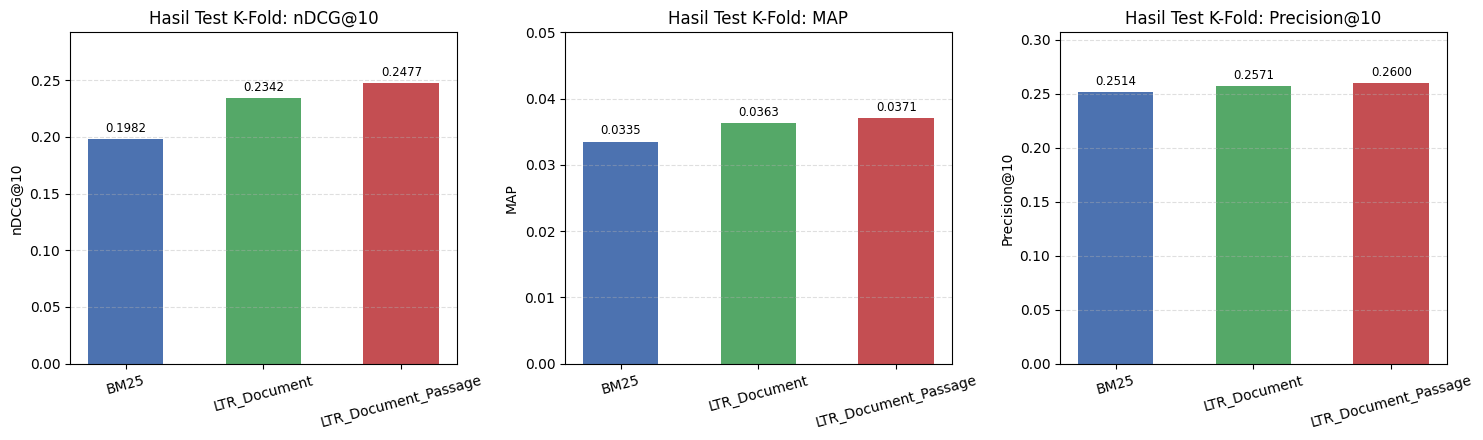

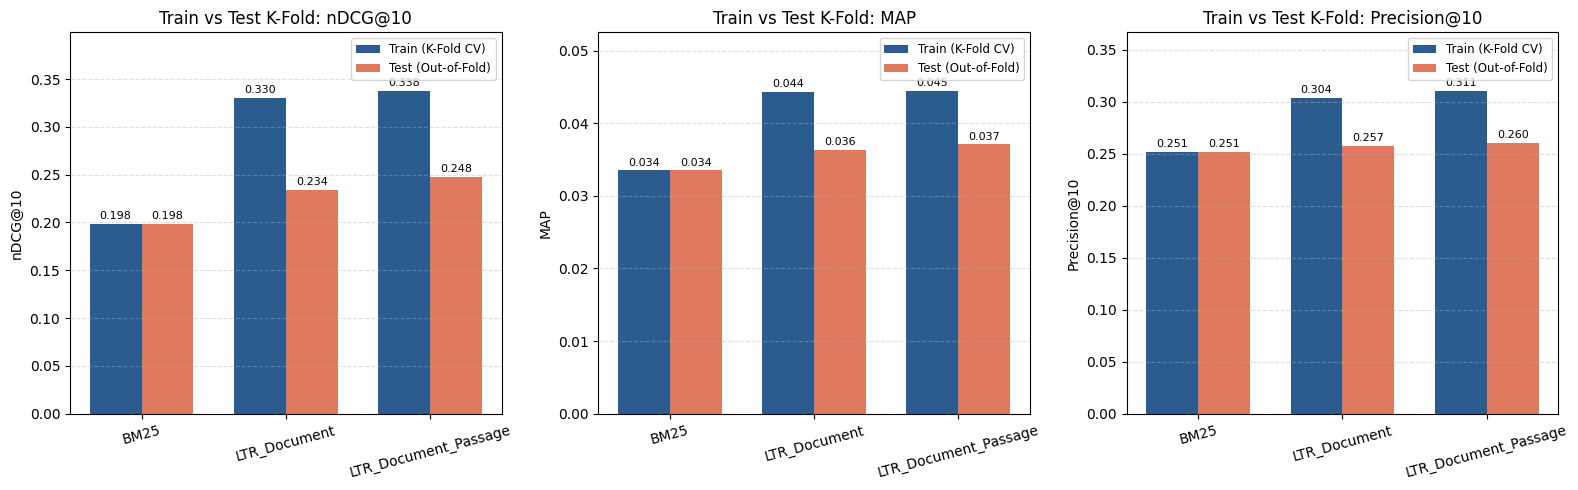

In [12]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from scipy.stats import wilcoxon

# Pastikan urutan sistem konsisten di seluruh tabel dan grafik
systems = ["BM25", "LTR_Document", "LTR_Document_Passage"]
system_colors = ["#4C72B0", "#55A868", "#C44E52"]
plot_metrics = ["nDCG@10", "MAP", "Precision@10"]
all_metrics_list = ["nDCG@10", "MAP", "Precision@10", "Recall@100"]


def diagnose_overfit(row, ndcg_warn=0.08, ndcg_high=0.15, map_warn=0.08, map_high=0.15):
    g_ndcg = row["gap_nDCG@10"]
    g_map = row["gap_MAP"]
    if g_ndcg >= ndcg_high or g_map >= map_high:
        return "Overfit Tinggi (Perketat regularisasi)"
    elif g_ndcg >= ndcg_warn or g_map >= map_warn:
        return "Overfit Ringan-Sedang (Pantau generalisasi)"
    elif g_ndcg < -0.03 and g_map < -0.03:
        return "Underfit / Varians Test Tinggi (Cek fitur/kapasitas)"
    else:
        return "Relatif Fit / Generalisasi Baik"


def safe_wilcoxon(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if np.allclose(x, y):
        return np.nan, 1.0
    stat, p_val = wilcoxon(x, y, zero_method="wilcox", alternative="two-sided")
    return stat, p_val


gkf = GroupKFold(n_splits=N_SPLITS)
groups = data["topic_id"].values
X_dummy = np.zeros(len(data))

all_predictions = []
all_train_predictions = []
train_fold_summaries = []
test_fold_summaries = []
feature_importances = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_dummy, data["judgment"], groups), start=1):
    train_data = data.iloc[train_idx].copy()
    test_data = data.iloc[test_idx].copy()
    test_topics = sorted(test_data["topic_id"].unique().tolist())

    # 1. SISTEM 1: BASELINE BM25 (TEST)
    baseline = test_data[["topic_id", "cord_uid", "bm25_score"]].rename(columns={"bm25_score": "predicted_score"})
    baseline["system"] = "BM25"
    baseline["fold"] = fold
    all_predictions.append(baseline)

    # 2. SISTEM 2: LTR DOCUMENT (TRAIN & TEST)
    model_doc = train_lambdamart(train_data, SYSTEM2_FEATURES)
    res_doc = test_data[["topic_id", "cord_uid"]].copy()
    res_doc["predicted_score"] = model_doc.predict(test_data[SYSTEM2_FEATURES])
    res_doc["system"] = "LTR_Document"
    res_doc["fold"] = fold
    all_predictions.append(res_doc)

    # 3. SISTEM 3: LTR DOCUMENT + PASSAGE (TRAIN & TEST)
    model_passage = train_lambdamart(train_data, SYSTEM3_FEATURES)
    res_passage = test_data[["topic_id", "cord_uid"]].copy()
    res_passage["predicted_score"] = model_passage.predict(test_data[SYSTEM3_FEATURES])
    res_passage["system"] = "LTR_Document_Passage"
    res_passage["fold"] = fold
    all_predictions.append(res_passage)

    # --- PREDIKSI & EVALUASI IN-SAMPLE TRAINING ---
    train_preds_fold = []

    tr_base = train_data[["topic_id", "cord_uid", "bm25_score"]].rename(columns={"bm25_score": "predicted_score"})
    tr_base["system"] = "BM25"
    tr_base["fold"] = fold
    train_preds_fold.append(tr_base)

    tr_doc = train_data[["topic_id", "cord_uid"]].copy()
    tr_doc["predicted_score"] = model_doc.predict(train_data[SYSTEM2_FEATURES])
    tr_doc["system"] = "LTR_Document"
    tr_doc["fold"] = fold
    train_preds_fold.append(tr_doc)

    tr_pass = train_data[["topic_id", "cord_uid"]].copy()
    tr_pass["predicted_score"] = model_passage.predict(train_data[SYSTEM3_FEATURES])
    tr_pass["system"] = "LTR_Document_Passage"
    tr_pass["fold"] = fold
    train_preds_fold.append(tr_pass)

    df_tr_pred = pd.concat(train_preds_fold, ignore_index=True)
    all_train_predictions.append(df_tr_pred)

    for sys_name in systems:
        sub_tr = df_tr_pred[df_tr_pred["system"] == sys_name]
        topic_tr_scores = [
            evaluate_ranking(tid, sub_tr[sub_tr["topic_id"] == tid], qrels)
            for tid in sorted(sub_tr["topic_id"].unique())
        ]
        mean_tr = pd.DataFrame(topic_tr_scores)[all_metrics_list].mean().to_dict()
        mean_tr["system"] = sys_name
        mean_tr["fold"] = fold
        train_fold_summaries.append(mean_tr)

    # Ringkasan metrik per fold untuk OUT-OF-FOLD TEST
    fold_test_preds = pd.concat([p for p in all_predictions[-3:]], ignore_index=True)
    for sys_name in systems:
        sub_te = fold_test_preds[fold_test_preds["system"] == sys_name]
        topic_te_scores = [
            evaluate_ranking(tid, sub_te[sub_te["topic_id"] == tid], qrels)
            for tid in sorted(sub_te["topic_id"].unique())
        ]
        mean_te = pd.DataFrame(topic_te_scores)[all_metrics_list].mean().to_dict()
        mean_te["system"] = sys_name
        mean_te["fold"] = fold
        test_fold_summaries.append(mean_te)

    feature_importances.append(pd.DataFrame({
        "feature": SYSTEM3_FEATURES,
        "importance": model_passage.feature_importances_,
        "fold": fold
    }))
    print(f"Fold {fold} selesai (Topik uji: {test_topics})")
    gc.collect()

predictions_df = pd.concat(all_predictions, ignore_index=True)
train_predictions_df = pd.concat(all_train_predictions, ignore_index=True)
train_fold_df = pd.DataFrame(train_fold_summaries)
test_fold_df = pd.DataFrame(test_fold_summaries)
importance_df = pd.concat(feature_importances, ignore_index=True)

# Evaluasi seluruh topik OUT-OF-FOLD TEST (pooled per topik)
all_metrics = []
for system in systems:
    sys_preds = predictions_df[predictions_df["system"] == system]
    for topic_id in sorted(sys_preds["topic_id"].unique()):
        topic_preds = sys_preds[sys_preds["topic_id"] == topic_id]
        res = evaluate_ranking(topic_id, topic_preds, qrels)
        res["system"] = system
        res["fold"] = int(topic_preds["fold"].iloc[0])
        all_metrics.append(res)

results = pd.DataFrame(all_metrics)

# 0. Rata-Rata Performa TRAINING (Rata-Rata K-Fold CV)
train_summary = (
    train_fold_df.groupby("system", sort=False)[all_metrics_list]
    .mean()
    .reindex(systems)
    .reset_index()
)
print("\n=== RATA-RATA PERFORMA TRAINING (KFOLD CV) ===")
print(train_summary.round(4).to_string(index=False))

# 1. Statistik Deskriptif Metrik Evaluasi Tiap Sistem (OUT-OF-FOLD TEST)
print("\n=== STATISTIK DESKRIPTIF METRIK EVALUASI TIAP SISTEM (TEST) ===")
desc_rows = []
for system in systems:
    print(f"\n--- Sistem: {system} ---")
    sys_desc = results[results["system"] == system][all_metrics_list].describe().round(4)
    print(sys_desc.to_string())
    sys_desc_export = sys_desc.reset_index().rename(columns={"index": "Statistik"})
    sys_desc_export.insert(0, "System", system)
    desc_rows.append(sys_desc_export)

desc_all_df = pd.concat(desc_rows, ignore_index=True)

# 2. Rata-Rata Performa Ketiga Sistem (OUT-OF-FOLD TEST)
summary = (
    results.groupby("system", sort=False)[all_metrics_list]
    .mean()
    .reindex(systems)
    .reset_index()
)
print("\n=== RATA-RATA PERFORMA KETIGA SISTEM (TEST) ===")
print(summary.round(4).to_string(index=False))

# Perbandingan berdampingan Train vs Test & Analisis Overfitting
comparison = train_summary[["system"] + all_metrics_list].merge(
    summary[["system"] + all_metrics_list],
    on="system",
    suffixes=("_train", "_test")
)
for m in all_metrics_list:
    comparison[f"gap_{m}"] = (comparison[f"{m}_train"] - comparison[f"{m}_test"]).round(4)

comparison["status_generalisasi"] = comparison.apply(diagnose_overfit, axis=1)

print("\n=== ANALISIS TABEL GENERALISASI / OVERFITTING (TRAIN VS TEST) ===")
print(comparison[[
    "system", "nDCG@10_train", "nDCG@10_test", "gap_nDCG@10",
    "MAP_train", "MAP_test", "gap_MAP", "status_generalisasi"
]].round(4).to_string(index=False))

# 3. Uji Signifikansi Wilcoxon (TEST)
print("\n=== UJI SIGNIFIKANSI WILCOXON (p-value - TEST) ===")
wilcoxon_rows = []
for sys_a, sys_b in [
    ("BM25", "LTR_Document"),
    ("BM25", "LTR_Document_Passage"),
    ("LTR_Document", "LTR_Document_Passage"),
]:
    df_a = results[results["system"] == sys_a].sort_values("topic_id").reset_index(drop=True)
    df_b = results[results["system"] == sys_b].sort_values("topic_id").reset_index(drop=True)
    row_res = {"Perbandingan": f"{sys_a} vs {sys_b}"}
    for m in plot_metrics:
        stat, p_val = safe_wilcoxon(df_a[m].values, df_b[m].values)
        row_res[f"{m} (stat)"] = round(stat, 4) if pd.notna(stat) else np.nan
        row_res[f"{m} (p-val)"] = round(p_val, 4)
        row_res[f"{m} (sig<0.05)"] = "Ya" if p_val < 0.05 else "Tidak"
    wilcoxon_rows.append(row_res)

wilcoxon_df = pd.DataFrame(wilcoxon_rows)
print(wilcoxon_df.to_string(index=False))

# 4. Rata-Rata Feature Importance (LTR_Document_Passage)
print("\n=== RATA-RATA FEATURE IMPORTANCE (LTR_Document_Passage) ===")
fi_summary = (
    importance_df.groupby("feature")["importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .reset_index()
    .rename(columns={"mean": "importance_mean", "std": "importance_std"})
)
print(fi_summary.round(4).to_string(index=False))

# Simpan seluruh hasil evaluasi ke CSV
desc_all_df.to_csv("statistik_deskriptif_tiap_sistem.csv", index=False)
summary.round(4).to_csv("rata_rata_performa_3_sistem.csv", index=False)
train_summary.round(4).to_csv("rata_rata_performa_training_3_sistem.csv", index=False)
train_fold_df.round(4).to_csv("evaluasi_training_per_fold.csv", index=False)
test_fold_df.round(4).to_csv("evaluasi_test_per_fold.csv", index=False)
comparison.round(4).to_csv("perbandingan_train_vs_test.csv", index=False)
wilcoxon_df.to_csv("hasil_uji_wilcoxon.csv", index=False)
fi_summary.round(4).to_csv("feature_importance_ltr_passage.csv", index=False)
results.to_csv("hasil_metrik_per_topik.csv", index=False)

# 5a. Grafik Batang Hasil Test K-Fold dari 3 Sistem Berdasarkan 3 Metrik
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for idx, metric in enumerate(plot_metrics):
    bars = axes[idx].bar(summary["system"], summary[metric], color=system_colors, width=0.55)
    axes[idx].set_title(f"Hasil Test K-Fold: {metric}")
    axes[idx].set_ylabel(metric)
    axes[idx].set_ylim(0, max(summary[metric].max() * 1.18, 0.05))
    axes[idx].tick_params(axis="x", rotation=15)
    axes[idx].grid(axis="y", linestyle="--", alpha=0.4)
    axes[idx].bar_label(bars, fmt="%.4f", padding=3, fontsize=8.5)

plt.tight_layout()
plt.savefig("grafik_test_3_sistem_3_metrik.png", dpi=300, bbox_inches="tight")
plt.show()

# 5b. Grafik Batang Perbandingan Hasil Train vs Test K-Fold dari 3 Sistem Berdasarkan 3 Metrik
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
x = np.arange(len(systems))
width = 0.36

for idx, metric in enumerate(plot_metrics):
    train_vals = comparison[f"{metric}_train"].values
    test_vals = comparison[f"{metric}_test"].values

    bars_tr = axes[idx].bar(x - width / 2, train_vals, width, label="Train (K-Fold CV)", color="#2B5C8F")
    bars_te = axes[idx].bar(x + width / 2, test_vals, width, label="Test (Out-of-Fold)", color="#E07A5F")

    max_val = max(train_vals.max(), test_vals.max())
    axes[idx].set_title(f"Train vs Test K-Fold: {metric}")
    axes[idx].set_ylabel(metric)
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(systems, rotation=15)
    axes[idx].set_ylim(0, max(max_val * 1.18, 0.05))
    axes[idx].grid(axis="y", linestyle="--", alpha=0.4)
    axes[idx].legend(loc="upper right", fontsize=8.5)
    axes[idx].bar_label(bars_tr, fmt="%.3f", padding=2, fontsize=8)
    axes[idx].bar_label(bars_te, fmt="%.3f", padding=2, fontsize=8)

plt.tight_layout()
plt.savefig("grafik_perbandingan_train_vs_test_3_sistem_3_metrik.png", dpi=300, bbox_inches="tight")
plt.show()

# Ringkasan Hasil (5-Fold GroupKFold, 35 Topik TREC-COVID Round 3)

- **Performa Test:** `LTR_Document_Passage` unggul rata-rata (`nDCG@10 = 0.2477`, `MAP = 0.0371`, `Precision@10 = 0.2600`) dibanding `LTR_Document` (`0.2342`, `0.0363`, `0.2571`) dan `BM25` (`0.1982`, `0.0335`, `0.2514`), dengan `Recall@100` sama (`0.1169`) di pool Top-100.
- **Wilcoxon (p-value):** `BM25 vs LTR_Document` signifikan pada `MAP` ($p = 0.0275$); `BM25 vs LTR_Document_Passage` marginal pada `nDCG@10` ($p = 0.0812$) dan `MAP` ($p = 0.0649$); `LTR_Document vs LTR_Document_Passage` tidak signifikan ($p > 0.62$).
- **Generalisasi (Train vs Test):** Baseline `BM25` tidak memiliki parameter pembelajaran sehingga skor *train* dan *test* identik (`gap = 0.0000` pada `nDCG@10 = 0.1982` dan `MAP = 0.0335`). Sebaliknya, model LambdaMART mencatat skor *train* lebih tinggi daripada *test*, dengan gap `nDCG@10` sebesar `+0.0957` pada `LTR_Document` (`0.3299` vs `0.2342`) dan `+0.0903` pada `LTR_Document_Passage` (`0.3380` vs `0.2477`), sementara gap `MAP` relatif kecil (`+0.0080` dan `+0.0074`). Hal ini menunjukkan *overfitting* ringan–sedang pada `nDCG@10`, namun penambahan fitur *passage* sedikit menekan gap sekaligus meningkatkan skor *test* tertinggi.
- **Feature Importance (FI):** Pada `LTR_Document_Passage` lintas *5-Fold GroupKFold*, empat fitur teratas berdasarkan rata-rata *split* adalah `bm25_score_norm` ($38.20 \pm 1.48$), `doc_length_norm` ($32.00 \pm 7.58$), `bm25_title_norm` ($28.00 \pm 11.40$), dan `passage_count_norm` ($23.80 \pm 4.97$). Stabilitas `bm25_score_norm` (SD rendah `1.48`) menjaga konsistensi peringkat lintas *fold*, sedangkan SD yang lebih lebar pada `bm25_title_norm` (`11.40`) dan `passage_mean_norm` (`10.76`) mencerminkan variasi karakteristik antar-topik yang sejalan dengan gap *train–test* moderat. Fitur tingkat *passage* (`passage_count_norm`, `passage_mean_norm`, `passage_peak_ratio_norm`, `passage_max_norm`) melampaui sebagian fitur dokumen (`bm25_abstract_norm = 13.00`), sehingga memberi sinyal tambahan untuk menyempurnakan peringkat atas tanpa memperburuk generalisasi.

**Kesimpulan:** Re-ranking LambdaMART memperbaiki rata-rata skor `BM25` pada 35 topik uji dengan dukungan statistik paling kuat pada `MAP` model dokumen serta tren marginal pada model dokumen + passage, meski selisih antar-kedua model LTR belum signifikan secara statistik.